# Валидация выборки отзывов

Таблица `data/interim/labels.csv`: 4800 отзывов восьми сфер, три класса. Ниже проверяются пустые строки, одинаковые тексты, баланс классов и длина. Короткий текст — меньше 10 символов. Выброс длины — за пределами 1.5 межквартильного размаха.

Запускать из корня репозитория.

In [1]:
import json
from pathlib import Path

from src.data.collect import SOURCE_NOTES
from src.data.validate import (
    LABEL_TITLES,
    VALID_LABELS,
    format_report,
    load_labels,
    validate_rows,
)

rows = load_labels(Path("data/interim/labels.csv"))
report = validate_rows(rows)
print(format_report(report))
print()
for source, counts in report["by_source"].items():
    titled = ", ".join(f"{LABEL_TITLES[label]} {counts[label]}" for label in VALID_LABELS)
    print(f"{SOURCE_NOTES.get(source, source)}: {titled}")

Строк: 4800
Классы: негатив 1602, нейтрально 1601, позитив 1597
Длина, символы: min 1, медиана 277.0, max 1499
Коротких (<10): 21. Выбросы длины: снизу 0, сверху 0
Групп одинакового текста: 5, лишних строк: 5
Проблемы:
- Одинаковый текст в разных строках: 5 групп, лишних строк 5.
- Классы близки (негатив 1602, нейтрально 1601, позитив 1597), отношение 1.00.
- Слишком коротких текстов (меньше 10 символов): 21.

отзывы об аниме: негатив 199, нейтрально 200, позитив 201
отзывы о банках: негатив 200, нейтрально 200, позитив 200
отзывы о местах: негатив 200, нейтрально 200, позитив 200
отзывы о фильмах: негатив 200, нейтрально 200, позитив 200
отзывы на продукты: негатив 200, нейтрально 200, позитив 200
отзывы на товары: негатив 201, нейтрально 201, позитив 198
отзывы на одежду и аксессуары: негатив 201, нейтрально 200, позитив 199
отзывы на банковское приложение: негатив 201, нейтрально 200, позитив 199


## Классы

Столбцы — число отзывов. Второй график смотрит, не спрятан ли перекос внутри отдельной сферы.

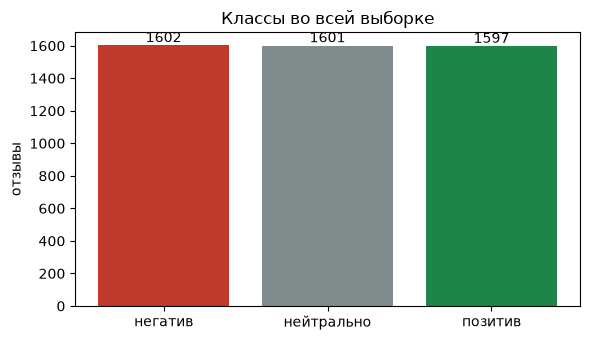

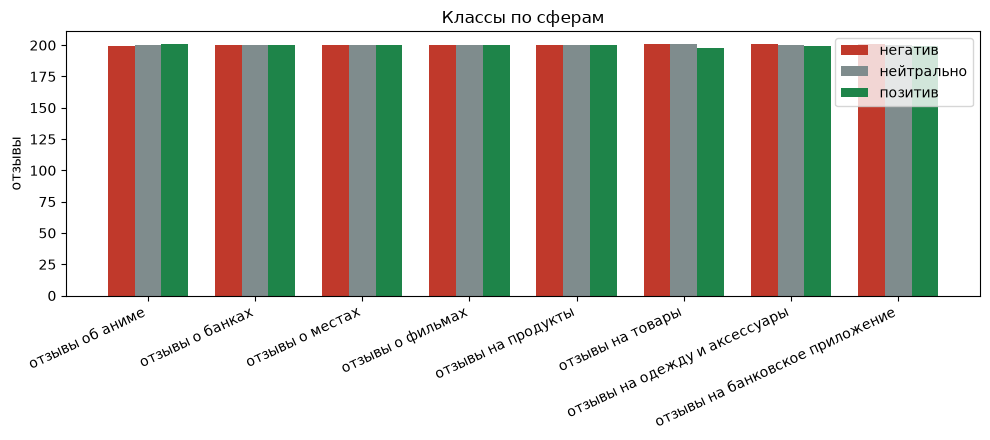

In [2]:
import matplotlib.pyplot as plt

COLORS = {"negative": "#c0392b", "neutral": "#7f8c8d", "positive": "#1e8449"}

fig, ax = plt.subplots(figsize=(6, 3.5))
labels = list(VALID_LABELS)
heights = [report["classes"][label] for label in labels]
bars = ax.bar(
    [LABEL_TITLES[label] for label in labels],
    heights,
    color=[COLORS[label] for label in labels],
)
ax.bar_label(bars)
ax.set_ylabel("отзывы")
ax.set_title("Классы во всей выборке")
fig.tight_layout()

fig, ax = plt.subplots(figsize=(10, 4.5))
sources = list(report["by_source"])
width = 0.25
for index, label in enumerate(labels):
    offset = (index - 1) * width
    ax.bar(
        [position + offset for position in range(len(sources))],
        [report["by_source"][source][label] for source in sources],
        width=width,
        color=COLORS[label],
        label=LABEL_TITLES[label],
    )
names = [SOURCE_NOTES[source] for source in sources]
ax.set_xticks(range(len(sources)), names, rotation=25, ha="right")
ax.set_ylabel("отзывы")
ax.set_title("Классы по сферам")
ax.legend()
fig.tight_layout()

## Длина, повторы и короткие тексты

Пунктир на гистограмме — границы выбросов. Нижняя граница здесь уходит ниже нуля, поэтому короткие отзывы ловит отдельное правило: меньше 10 символов. Повтор — тот же текст в двух строках, даже если перевод строки записан по-разному.

Повторы:
- ['ru-reviews-classification', 'rureviews']: Заказала L на бедра 99см даже не налезла,маломерка 
Качество за эти деньги норм...
- ['rureviews', 'ru-reviews-classification']: Качество юбки очень порадовало: швы ровные, края обработаны, молния вшита хорошо. Смущает вырез сзади, кажется он может 
- ['ru-reviews-classification', 'rureviews']: Продавец прислал юбку с производственным браком. Отсутствовала треть складок, остальные были кривые и разной ширины. К т
- ['ru-reviews-classification', 'rureviews']: норма
, но одной пуговицы нет
- ['ru-reviews-classification', 'rureviews']: пришло достаточно быстро, хорошее качество, приятная к телу,
продавец очень хороший, отвечает своевременно

Короткие тексты:
- id 1551, 1 симв., rureviews: c
- id 2471, 1 симв., sber: 👌
- id 2885, 1 симв., sber: 🏦
- id 3119, 2 симв., rureviews: Ну
- id 2892, 3 симв., sber: 👍🇷🇺
- id 2897, 3 симв., perekrestok: Мрр
- id 2480, 4 симв., rureviews: малы
- id 2924, 4 симв., ru-reviews-classification: рьтд


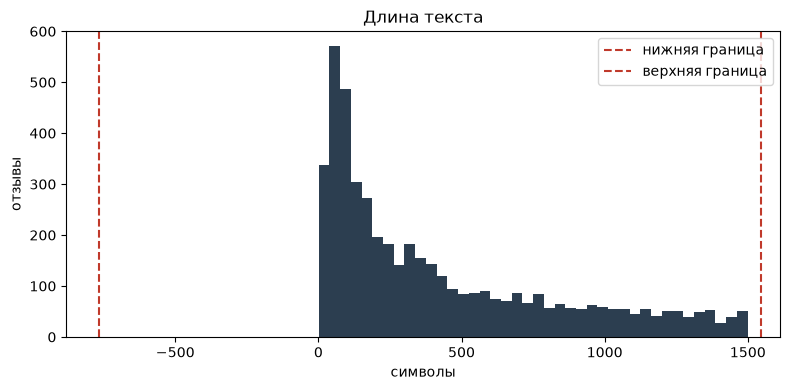

In [3]:
lengths = [len(row["text"].strip()) for row in rows if row["text"].strip()]
length = report["length"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(lengths, bins=40, color="#2c3e50")
ax.axvline(length["low_fence"], color="#c0392b", linestyle="--", label="нижняя граница")
ax.axvline(length["high_fence"], color="#c0392b", linestyle="--", label="верхняя граница")
ax.set_xlabel("символы")
ax.set_ylabel("отзывы")
ax.set_title("Длина текста")
ax.legend()
fig.tight_layout()

print("Повторы:")
for item in report["duplicates"]["examples"]:
    print(f"- {item['sources']}: {item['text']}")

print("\nКороткие тексты:")
for item in report["short_examples"]:
    print(f"- id {item['review_id']}, {item['length']} симв., {item['source']}: {item['text']}")

## Что известно о выборке

Размер и баланс берутся из отчёта выше. Шум автоматических меток — из пилота T1.2: человек разметил 50 отзывов, не видя исходную метку.

In [4]:
agreement = json.loads(Path("data/interim/pilot_agreement.json").read_text(encoding="utf-8"))
print(
    f"Пилот: совпало {agreement['matched']} из {agreement['pilot_size']} "
    f"({agreement['agreement']}). "
    f"Ручных меток {agreement['manual_rows']}, исходных {agreement['source_rows']}."
)
print("Совпадение по сферам:")
for source, score in agreement["by_source"].items():
    print(f"- {SOURCE_NOTES.get(source, source)}: {score['match']} из {score['total']}")

Пилот: совпало 31 из 50 (0.62). Ручных меток 50, исходных 4750.
Совпадение по сферам:
- отзывы об аниме: 3 из 7
- отзывы о банках: 6 из 6
- отзывы о местах: 6 из 6
- отзывы о фильмах: 4 из 6
- отзывы на продукты: 4 из 6
- отзывы на товары: 2 из 7
- отзывы на одежду и аксессуары: 2 из 6
- отзывы на банковское приложение: 4 из 6
